# Notebook 05: Results, Validation Checks, and Thesis Figures

Reads data/evaluation_results.json from Notebook 04 and produces
everything the Results chapter needs:

  1. Main results table (correctness per batch and pipeline, with
     95% confidence intervals)
  2. Significance test: is the RAG-vs-CAG gap real or noise?
     (McNemar's test, since both pipelines answer the same questions)
  3. Judge validation: does Gemini's grading track whether the
     answer was actually knowable? (the check we discussed)
  4. RAG retrieval-quality table
  5. Three figures, saved as PNG and PDF in figures/
  6. A blind manual spot-check sheet, plus the agreement calculation
     once you've filled it in

No GPU, no API calls, runs in a few seconds. Tables go to tables/,
figures to figures/, both inside your thesis-rag-cag Drive folder.

## Cell 0: Mount Drive and move into the project folder

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/thesis-rag-cag')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cell 1: Imports and config

In [5]:
import json
import math
import random

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

DATA_DIR = "data"
FIG_DIR = "figures"
TABLE_DIR = "tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

EVAL_PATH = os.path.join(DATA_DIR, "evaluation_results.json")
SPOT_CHECK_BLIND_PATH = os.path.join(DATA_DIR, "spot_check_blind.csv")
SPOT_CHECK_FILLED_PATH = os.path.join(DATA_DIR, "spot_check_filled.csv")

BATCHES = ["week1", "week2", "week3"]
PIPELINES = ["rag", "cag"]
LABELS = {"rag": "RAG", "cag": "CAG"}

# Colors: one fixed color per pipeline, used in every figure (checked for
# colorblind separation). Text always uses the ink colors, never the series color.
COLORS = {"rag": "#2a78d6", "cag": "#eb6834"}
INK = "#1f1f1e"
INK_2 = "#5f5e58"
GRID = "#e6e5e0"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

with open(EVAL_PATH) as f:
    records = json.load(f)

df = pd.DataFrame(records)
missing = df["judged_correct"].isna().sum()
df = df[df["judged_correct"].notna()].copy()
df["judged_correct"] = df["judged_correct"].astype(bool)
print(f"Loaded {len(df)} judged records ({missing} without a verdict, excluded).")

# Corpus size per batch, read from the CAG bookkeeping (included + dropped).
cag_rows = df[df["pipeline"] == "cag"]
corpus_size = {
    b: int((cag_rows[cag_rows["batch"] == b]["articles_included"]
            + cag_rows[cag_rows["batch"] == b]["articles_dropped"]).iloc[0])
    for b in BATCHES
}
cag_fit = {
    b: int(cag_rows[cag_rows["batch"] == b]["articles_included"].iloc[0])
    for b in BATCHES
}
print("Corpus size per batch:", corpus_size)
print("Articles that fit in CAG's context:", cag_fit)


def wilson_ci(k, n, z=1.96):
    """95% confidence interval for a proportion (Wilson method — behaves
    better than the textbook formula near 0% and 100%)."""
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return centre - half, centre + half

Loaded 1718 judged records (0 without a verdict, excluded).
Corpus size per batch: {'week1': 30, 'week2': 75, 'week3': 369}
Articles that fit in CAG's context: {'week1': 30, 'week2': 45, 'week3': 45}


## Cell 2: Main results table

In [6]:
rows = []
for b in BATCHES:
    for p in PIPELINES:
        sub = df[(df["batch"] == b) & (df["pipeline"] == p)]
        n, k = len(sub), int(sub["judged_correct"].sum())
        lo, hi = wilson_ci(k, n)
        fact = sub[sub["question_type"] == "factual"]["judged_correct"].mean()
        reas = sub[sub["question_type"] == "reasoning"]["judged_correct"].mean()
        rows.append({
            "batch": b,
            "corpus_articles": corpus_size[b],
            "pipeline": LABELS[p],
            "n_questions": n,
            "correct": k,
            "accuracy_pct": round(100 * k / n, 1),
            "ci95_low_pct": round(100 * lo, 1),
            "ci95_high_pct": round(100 * hi, 1),
            "factual_pct": round(100 * fact, 1),
            "reasoning_pct": round(100 * reas, 1),
        })

results_table = pd.DataFrame(rows)
results_table.to_csv(os.path.join(TABLE_DIR, "main_results.csv"), index=False)
print(results_table.to_string(index=False))

batch  corpus_articles pipeline  n_questions  correct  accuracy_pct  ci95_low_pct  ci95_high_pct  factual_pct  reasoning_pct
week1               30      RAG           54       48          88.9          77.8           94.8         85.2           92.6
week1               30      CAG           54       50          92.6          82.4           97.1         96.3           88.9
week2               75      RAG          135      124          91.9          86.0           95.4         92.3           91.4
week2               75      CAG          135       75          55.6          47.1           63.7         61.5           50.0
week3              369      RAG          670      619          92.4          90.1           94.2         92.3           92.5
week3              369      CAG          670       84          12.5          10.2           15.3         12.8           12.3


## Cell 3: Significance test — McNemar's test per batch

In [7]:
# Both pipelines answer the SAME questions, so we compare them pair by
# pair. Only the questions where they disagree matter:
#   b = RAG right, CAG wrong      c = RAG wrong, CAG right
# If the pipelines were equally good, b and c would be roughly equal.
# The exact test asks how unlikely the observed split is under that
# assumption. p < 0.05 = the difference is very unlikely to be chance.

sig_rows = []
for b in BATCHES:
    sub = df[df["batch"] == b]
    paired = sub.pivot_table(index="qa_id", columns="pipeline",
                             values="judged_correct", aggfunc="first").dropna()
    rag_only = int((paired["rag"] & ~paired["cag"]).sum())
    cag_only = int((~paired["rag"] & paired["cag"]).sum())
    both = int((paired["rag"] & paired["cag"]).sum())
    neither = int((~paired["rag"] & ~paired["cag"]).sum())
    discordant = rag_only + cag_only
    p_value = binomtest(min(rag_only, cag_only), discordant, 0.5).pvalue if discordant else 1.0
    sig_rows.append({
        "batch": b,
        "paired_questions": len(paired),
        "both_correct": both,
        "rag_only_correct": rag_only,
        "cag_only_correct": cag_only,
        "neither_correct": neither,
        "mcnemar_exact_p": p_value,
    })

sig_table = pd.DataFrame(sig_rows)
sig_table.to_csv(os.path.join(TABLE_DIR, "significance_mcnemar.csv"), index=False)
pd.set_option("display.float_format", lambda x: f"{x:.3g}")
print(sig_table.to_string(index=False))

batch  paired_questions  both_correct  rag_only_correct  cag_only_correct  neither_correct  mcnemar_exact_p
week1                54            47                 1                 3                3            0.625
week2               135            70                54                 5                6         1.91e-11
week3               670            79               540                 5               46        6.89e-153


## Cell 4: Judge validation — does the grading make sense?

In [8]:
# If Gemini were just saying "correct" to everything, CAG would score
# about the same whether or not the source article was in its context.
# A trustworthy judge should show a big gap: high when the article was
# there, low when it was cut off (the model couldn't have known).

val_rows = []
for b in BATCHES:
    cag_b = df[(df["batch"] == b) & (df["pipeline"] == "cag")]
    for included, label in [(True, "source in context"), (False, "source cut off")]:
        sub = cag_b[cag_b["source_article_included"] == included]
        if len(sub):
            val_rows.append({"pipeline": "CAG", "batch": b, "group": label,
                             "n": len(sub),
                             "accuracy_pct": round(100 * sub["judged_correct"].mean(), 1)})
    rag_b = df[(df["batch"] == b) & (df["pipeline"] == "rag")]
    for retrieved, label in [(True, "source retrieved"), (False, "source not retrieved")]:
        sub = rag_b[rag_b["source_article_retrieved"] == retrieved]
        if len(sub):
            val_rows.append({"pipeline": "RAG", "batch": b, "group": label,
                             "n": len(sub),
                             "accuracy_pct": round(100 * sub["judged_correct"].mean(), 1)})

validation_table = pd.DataFrame(val_rows)
validation_table.to_csv(os.path.join(TABLE_DIR, "judge_validation.csv"), index=False)
print(validation_table.to_string(index=False))

# Second check: answers where the model said it couldn't find the info.
# These should almost never be graded correct, since every reference
# answer in the dataset is a concrete fact.
not_stated = df["generated_answer"].str.lower().str.contains("not stated in the provided")
print(f"\n'Not stated' answers: {int(not_stated.sum())}, "
      f"of which judged correct: {int(df[not_stated]['judged_correct'].sum())}")

oom = df["generated_answer"].str.contains("OOM Error", na=False)
print(f"OOM fallback answers (should be 0): {int(oom.sum())}")

pipeline batch                group   n  accuracy_pct
     CAG week1    source in context  54          92.6
     RAG week1     source retrieved  52          92.3
     RAG week1 source not retrieved   2             0
     CAG week2    source in context  80          91.2
     CAG week2       source cut off  55           3.6
     RAG week2     source retrieved 132          93.2
     RAG week2 source not retrieved   3          33.3
     CAG week3    source in context  80          91.2
     CAG week3       source cut off 590           1.9
     RAG week3     source retrieved 649          94.6
     RAG week3 source not retrieved  21          23.8

'Not stated' answers: 537, of which judged correct: 0
OOM fallback answers (should be 0): 0


## Cell 5: RAG retrieval-quality table

In [9]:
def retrieval_metrics(sub):
    hits = {k: 0 for k in (1, 3, 5)}
    rr, ndcg = 0.0, 0.0
    for _, r in sub.iterrows():
        ids = list(r["retrieved_article_ids"])
        src = r["source_article_id"]
        for k in hits:
            hits[k] += src in ids[:k]
        if src in ids:
            rank = ids.index(src) + 1
            rr += 1 / rank
            if rank <= 5:
                ndcg += 1 / math.log2(rank + 1)
    n = len(sub)
    out = {f"hit@{k}": round(v / n, 3) for k, v in hits.items()}
    out["MRR"] = round(rr / n, 3)
    out["nDCG@5"] = round(ndcg / n, 3)
    return out

retr_rows = []
for b in BATCHES:
    sub = df[(df["batch"] == b) & (df["pipeline"] == "rag")]
    retr_rows.append({"batch": b, "corpus_articles": corpus_size[b],
                      "n": len(sub), **retrieval_metrics(sub)})

retrieval_table = pd.DataFrame(retr_rows)
retrieval_table.to_csv(os.path.join(TABLE_DIR, "rag_retrieval.csv"), index=False)
print(retrieval_table.to_string(index=False))

batch  corpus_articles   n  hit@1  hit@3  hit@5   MRR  nDCG@5
week1               30  54  0.852  0.963  0.963 0.904    0.92
week2               75 135  0.881  0.978  0.978 0.927    0.94
week3              369 670  0.858  0.958  0.969 0.904   0.921


## Cell 6: Figure 1 — answer correctness vs corpus size

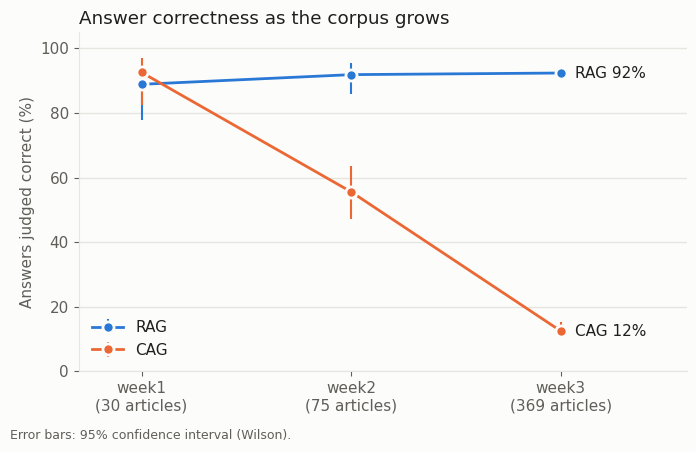

In [10]:
x = list(range(len(BATCHES)))
xlabels = [f"{b}\n({corpus_size[b]} articles)" for b in BATCHES]

fig, ax = plt.subplots(figsize=(7, 4.5))
for p in PIPELINES:
    t = results_table[results_table["pipeline"] == LABELS[p]]
    acc = t["accuracy_pct"].tolist()
    lo = (t["accuracy_pct"] - t["ci95_low_pct"]).tolist()
    hi = (t["ci95_high_pct"] - t["accuracy_pct"]).tolist()
    ax.errorbar(x, acc, yerr=[lo, hi], color=COLORS[p], linewidth=2,
                marker="o", markersize=8, markeredgecolor=SURFACE,
                markeredgewidth=2, capsize=0, elinewidth=1.5, label=LABELS[p])
    ax.annotate(f"{LABELS[p]} {acc[-1]:.0f}%", xy=(x[-1], acc[-1]),
                xytext=(10, 0), textcoords="offset points",
                va="center", color=INK, fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(xlabels)
ax.set_xlim(-0.3, len(BATCHES) - 0.4)
ax.set_ylim(0, 105)
ax.set_ylabel("Answers judged correct (%)")
ax.set_title("Answer correctness as the corpus grows", loc="left")
ax.yaxis.grid(True, color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left", labelcolor=INK)
fig.text(0.01, 0.01, "Error bars: 95% confidence interval (Wilson).",
         color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 1))
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG_DIR, f"fig1_correctness_vs_corpus.{ext}"), dpi=200)
plt.show()

## Cell 7: Figure 2 — how much of the corpus fits in CAG's context

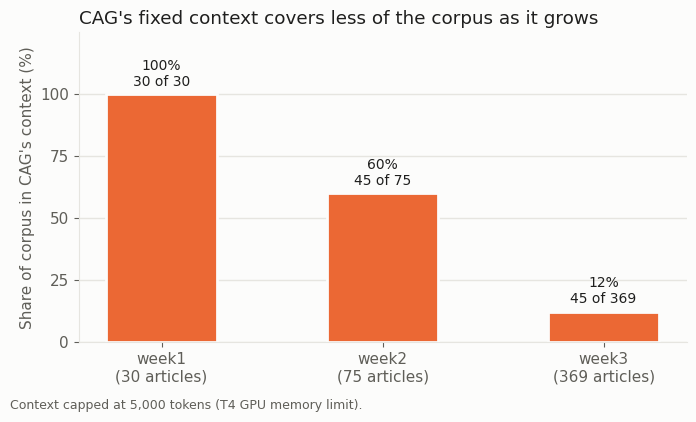

In [11]:
share = [100 * cag_fit[b] / corpus_size[b] for b in BATCHES]

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(x, share, width=0.5, color=COLORS["cag"], edgecolor=SURFACE, linewidth=2)
for xi, b, s in zip(x, BATCHES, share):
    ax.annotate(f"{s:.0f}%\n{cag_fit[b]} of {corpus_size[b]}", xy=(xi, s),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", color=INK, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(xlabels)
ax.set_ylim(0, 125)
ax.set_yticks(range(0, 101, 25))
ax.set_ylabel("Share of corpus in CAG's context (%)")
ax.set_title("CAG's fixed context covers less of the corpus as it grows", loc="left")
ax.yaxis.grid(True, color=GRID, linewidth=1)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, "Context capped at 5,000 tokens (T4 GPU memory limit).",
         color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 1))
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG_DIR, f"fig2_cag_context_coverage.{ext}"), dpi=200)
plt.show()

## Cell 8: Figure 3 — CAG correctness, source in context vs cut off

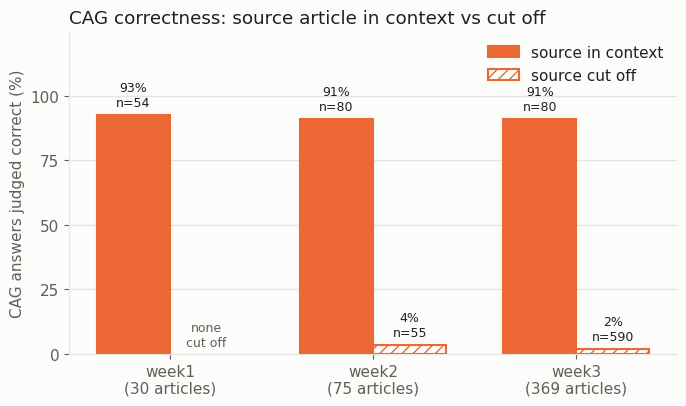

Saved figures to figures/ and tables to tables/


In [12]:
cag_val = validation_table[validation_table["pipeline"] == "CAG"]
width = 0.36

fig, ax = plt.subplots(figsize=(7, 4.2))
for offset, group, hatch in [(-width / 2, "source in context", None),
                             (width / 2, "source cut off", "///")]:
    vals, ns = [], []
    for b in BATCHES:
        row = cag_val[(cag_val["batch"] == b) & (cag_val["group"] == group)]
        vals.append(row["accuracy_pct"].iloc[0] if len(row) else float("nan"))
        ns.append(int(row["n"].iloc[0]) if len(row) else 0)
    ax.bar([xi + offset for xi in x], vals, width=width,
           color=COLORS["cag"] if hatch is None else SURFACE,
           edgecolor=COLORS["cag"], hatch=hatch, linewidth=1.5, label=group)
    for xi, v, n in zip(x, vals, ns):
        if n:
            ax.annotate(f"{v:.0f}%\nn={n}", xy=(xi + offset, v), xytext=(0, 4),
                        textcoords="offset points", ha="center", va="bottom",
                        color=INK, fontsize=9)
        else:
            ax.annotate("none\ncut off", xy=(xi + offset, 2), ha="center",
                        va="bottom", color=INK_2, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(xlabels)
ax.set_ylim(0, 125)
ax.set_yticks(range(0, 101, 25))
ax.set_ylabel("CAG answers judged correct (%)")
ax.set_title("CAG correctness: source article in context vs cut off", loc="left")
ax.yaxis.grid(True, color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", labelcolor=INK)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG_DIR, f"fig3_cag_source_in_context.{ext}"), dpi=200)
plt.show()

print(f"Saved figures to {FIG_DIR}/ and tables to {TABLE_DIR}/")

## Cell 9: Make the blind manual spot-check sheet

In [13]:
# 30 answers (5 per batch x pipeline), WITHOUT Gemini's verdict, so your
# own judgment isn't influenced. Open data/spot_check_blind.csv in Google
# Sheets, fill the my_verdict column with 1 (correct) or 0 (incorrect)
# using the same rule the judge used: same meaning as the reference
# answer = correct. Then File > Download > CSV, rename it to
# spot_check_filled.csv, and upload it into the data/ folder.

random.seed(42)
sample_parts = []
for b in BATCHES:
    for p in PIPELINES:
        sub = df[(df["batch"] == b) & (df["pipeline"] == p)]
        sample_parts.append(sub.sample(n=min(5, len(sub)), random_state=random.randint(0, 10**6)))

spot = pd.concat(sample_parts).sample(frac=1, random_state=7)  # shuffle so pipelines are mixed
spot_blind = spot[["qa_id", "batch", "pipeline", "question",
                   "reference_answer", "generated_answer"]].copy()
spot_blind["my_verdict"] = ""
spot_blind.to_csv(SPOT_CHECK_BLIND_PATH, index=False)
print(f"Wrote {len(spot_blind)} rows to {SPOT_CHECK_BLIND_PATH}. Fill in my_verdict (1 or 0).")

Wrote 30 rows to data/spot_check_blind.csv. Fill in my_verdict (1 or 0).


## Cell 10: Human vs judge agreement (run after filling the sheet)

In [16]:
if not os.path.exists(SPOT_CHECK_FILLED_PATH):
    print(f"{SPOT_CHECK_FILLED_PATH} not found yet — fill in the spot-check sheet first.")
else:
    filled = pd.read_csv(SPOT_CHECK_FILLED_PATH)
    filled = filled[filled["my_verdict"].astype(str).str.strip().isin(["0", "1"])]
    filled["my_verdict"] = filled["my_verdict"].astype(int).astype(bool)
    merged = filled.merge(df[["qa_id", "batch", "pipeline", "judged_correct", "judge_reason"]],
                          on=["qa_id", "batch", "pipeline"])
    n = len(merged)
    agree = (merged["my_verdict"] == merged["judged_correct"]).sum()

    # Cohen's kappa: agreement corrected for the agreement you'd get by chance.
    p_obs = agree / n
    p_h = merged["my_verdict"].mean()
    p_j = merged["judged_correct"].mean()
    p_exp = p_h * p_j + (1 - p_h) * (1 - p_j)
    kappa = (p_obs - p_exp) / (1 - p_exp) if p_exp < 1 else float("nan")

    print(f"Human vs Gemini judge: agreed on {agree}/{n} = {100 * p_obs:.1f}%")
    print(f"Cohen's kappa = {kappa:.2f}  (above 0.8 = almost perfect, 0.6-0.8 = substantial)")

    disagreements = merged[merged["my_verdict"] != merged["judged_correct"]]
    if len(disagreements):
        print("\nDisagreements (worth reading, and mentioning in the thesis):")
        for _, r in disagreements.iterrows():
            print(f"- {r['qa_id']} {r['batch']} {r['pipeline']}: you={r['my_verdict']}, "
                  f"judge={r['judged_correct']} | {r['judge_reason'][:150]}")

Human vs Gemini judge: agreed on 29/30 = 96.7%
Cohen's kappa = 0.91  (above 0.8 = almost perfect, 0.6-0.8 = substantial)

Disagreements (worth reading, and mentioning in the thesis):
- qa_0152 week3 rag: you=True, judge=False | The generated answer includes 'agentic work', which is not mentioned in the reference answer as a specific task for the Beam model.


## Cell 11: Full corpus size in tokens

In [15]:
!pip install transformers -q
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-4B")
sep = len(tok.encode("\n\n---\n\n", add_special_tokens=False))

for week in ["week1", "week2", "week3"]:
    with open(f"data/{week}.json") as f:
        arts = json.load(f)
    tokens = sum(len(tok.encode(f"[{a['title']}]\n{a['text']}", add_special_tokens=False)) for a in arts)
    tokens += sep * (len(arts) - 1)
    print(f"{week}: {len(arts)} articles = {tokens:,} tokens "
          f"({'fits' if tokens <= 32768 else 'does NOT fit'} in Qwen3-4B's 32,768-token window)")

week1: 30 articles = 3,391 tokens (fits in Qwen3-4B's 32,768-token window)
week2: 75 articles = 8,473 tokens (fits in Qwen3-4B's 32,768-token window)
week3: 369 articles = 42,565 tokens (does NOT fit in Qwen3-4B's 32,768-token window)
